# Chapter 7 - Capacity expansion: what to build, and a CO2 cap that bites

Every chapter so far took the power plants as given and asked *how to operate*
them. Planning asks the harder question: **what should we build?** PyPSA answers
it by making a component's capacity a *decision variable* (`p_nom_extendable`)
and adding its **annualised build cost** to the objective. The solver then
minimises **capital + operating cost together**.

This is also where a **CO2 cap** finally changes the answer. In a pure dispatch
model the cheapest plants here are already the cleanest, so a carbon limit does
nothing. Once the model can *build*, the cap forces it to invest in more solar
and storage - at a cost we can measure exactly.

**Goals of this chapter**
- Make solar, wind and a battery **extendable** and read the optimal build.
- Split the total cost into **capital** and **operating** parts.
- Sweep a CO2 cap and draw the **cost-vs-carbon trade-off curve**.
- Meet the **feasibility wall**: why a short battery cannot decarbonise the night.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
gens_t = pd.read_excel(XLS, "generators_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
CO2 = dict(zip(carriers.name, carriers.co2_emissions))
COLORS = dict(zip(carriers.name, carriers.color))

### 7.1 The annualised capital cost

A solar farm is paid for once but runs for decades. To compare it with one day
of fuel, we spread its build cost over its lifetime and express it **per day**:

> capital_cost = (1 + FOM) * investment / (lifetime * 365.25)

`investment` is the overnight cost per MW, `FOM` the yearly fixed O&M as a
fraction, `lifetime` the years of service. Our optimisation horizon is one
representative day, so a per-day capital cost trades off correctly against the
day's fuel bill.

In [2]:
CAP = {c.name: (1 + c.FOM) * c.investment / (c.lifetime * 365.25)
       for c in carriers.itertuples()}
print("Annualised capital cost (per MW per day):")
for k in ["Solar", "Wind", "Battery"]:
    print(f"  {k:8s} {CAP[k]:7.1f}   (marginal cost {MC[k]:.2f}/MWh)")

Annualised capital cost (per MW per day):
  Solar      163.3   (marginal cost 0.01/MWh)
  Wind       270.3   (marginal cost 1.59/MWh)
  Battery     40.3   (marginal cost 0.00/MWh)


### 7.2 Build the expansion model

The **existing fleet** (diesel, hydro, the grid cable) keeps its fixed capacity.
We add three **candidate** investments with `p_nom_extendable=True` and an upper
limit `p_nom_max` that represents how much land / how many good sites the island
has. The battery is a `StorageUnit` with `max_hours=8` (an 8-hour energy store).

In [3]:
def expansion(co2_cap=None):
    n = pypsa.Network()
    n.set_snapshots(loads_t.index)
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    # existing fleet: capacity fixed
    for g in gens.itertuples():
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=g.p_nom, marginal_cost=MC[g.carrier])
    # candidate new build: capacity is a decision variable, capped by siting
    n.add("Generator", "SOLAR_new", bus="07TAPAL", carrier="Solar",
          p_nom_extendable=True, p_nom_max=150, capital_cost=CAP["Solar"],
          marginal_cost=MC["Solar"], p_max_pu=gens_t["SOLAR_BOHOL"].values)
    n.add("Generator", "WIND_new", bus="07UBAY", carrier="Wind",
          p_nom_extendable=True, p_nom_max=30, capital_cost=CAP["Wind"],
          marginal_cost=MC["Wind"], p_max_pu=gens_t["WIND_BOHOL"].values)
    n.add("StorageUnit", "BATT_new", bus="07UBAY", carrier="Battery",
          p_nom_extendable=True, p_nom_max=200, capital_cost=CAP["Battery"],
          max_hours=8, marginal_cost=0.0, efficiency_dispatch=0.95,
          efficiency_store=1.0, cyclic_state_of_charge=True)
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=loads_t[col].values)
    if co2_cap is not None:
        n.add("GlobalConstraint", "co2_limit", carrier_attribute="co2_emissions",
              sense="<=", constant=co2_cap)
    return n

OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

def emissions(n):
    return float((n.generators_t.p.sum() * n.generators.carrier.map(CO2)).sum())

### 7.3 The least-cost build (no carbon policy)

First we let cost alone decide. Note the result before reading on: on this windy,
sunny day the solver **chooses** a largely renewable island - clean energy is not
a sacrifice here, it is the cheapest plan.

In [4]:
base = expansion()
base.optimize(**OPT)

build = pd.Series({
    "solar (MW)": base.generators.p_nom_opt["SOLAR_new"],
    "wind (MW)": base.generators.p_nom_opt["WIND_new"],
    "battery (MW)": base.storage_units.p_nom_opt["BATT_new"],
})
e0 = emissions(base)
print("Optimal new build:"); print(build.round(1).to_string())
print(f"\nTotal cost: {base.objective:,.0f} per day | CO2: {e0:.1f} tonnes")

Optimal new build:
solar (MW)      105.2
wind (MW)        30.0
battery (MW)     36.3

Total cost: 41,138 per day | CO2: 35.1 tonnes


### 7.4 Capital vs operating cost

The objective is the sum of **capital** (building the new solar/wind/battery) and
**operating** cost (fuel for whatever still runs). Splitting them shows where the
money goes.

In [5]:
cap_cost = (base.generators.p_nom_opt[["SOLAR_new", "WIND_new"]]
            * pd.Series({"SOLAR_new": CAP["Solar"], "WIND_new": CAP["Wind"]})).sum()
cap_cost += base.storage_units.p_nom_opt["BATT_new"] * CAP["Battery"]
op_cost = (base.generators_t.p.sum() * base.generators.marginal_cost).sum()
print(f"Capital cost (new build)   : {cap_cost:8,.0f} per day")
print(f"Operating cost (fuel, etc.): {op_cost:8,.0f} per day")
print(f"Total                      : {cap_cost + op_cost:8,.0f} per day")
E = base.generators_t.p.T.groupby(base.generators.carrier).sum().T.sum()
print("\nEnergy by source (MWh):"); print(E.round(0).to_string())

Capital cost (new build)   :   26,750 per day
Operating cost (fuel, etc.):   14,388 per day
Total                      :   41,138 per day

Energy by source (MWh):
carrier
Diesel      0.0
Grid      319.0
Hydro     238.0
Solar     494.0
Wind      474.0


### 7.5 A CO2 cap that bites

Now tighten a carbon cap step by step, from today's emissions down. Each step the
solver must **invest more** (more solar, more battery) to burn less. We record the
cost and the build at every level to draw the trade-off curve.

In [6]:
rows = []
for frac in [1.00, 0.90, 0.85, 0.80, 0.75, 0.72, 0.70, 0.68, 0.60]:
    cap = None if frac == 1.00 else e0 * frac
    m = expansion(co2_cap=cap)
    status, _ = m.optimize(**OPT)
    if status != "ok":
        rows.append({"CO2 cap (t)": round(e0 * frac, 1), "feasible": "NO",
                     "cost": np.nan, "extra %": np.nan,
                     "solar": np.nan, "battery": np.nan})
        continue
    rows.append({"CO2 cap (t)": round(e0 * frac, 1), "feasible": "yes",
                 "cost": round(m.objective), "extra %": round(100 * (m.objective / base.objective - 1), 1),
                 "solar": round(m.generators.p_nom_opt["SOLAR_new"]),
                 "battery": round(m.storage_units.p_nom_opt["BATT_new"])})
curve = pd.DataFrame(rows)
print(curve.to_string(index=False))

 CO2 cap (t) feasible    cost  extra %  solar  battery
        35.1      yes 41138.0      0.0  105.0     36.0
        31.6      yes 41439.0      0.7  114.0     41.0
        29.8      yes 41872.0      1.8  121.0     41.0
        28.1      yes 42579.0      3.5  129.0     41.0
        26.3      yes 43567.0      5.9  140.0     41.0
        25.3      yes 44160.0      7.3  146.0     41.0
        24.6      yes 44561.0      8.3  150.0     41.0
        23.9       NO     NaN      NaN    NaN      NaN
        21.1       NO     NaN      NaN    NaN      NaN


### 7.6 The trade-off curve and the feasibility wall

Plotting cost against the carbon cap shows the classic shape: cheap at first, then
steepening as each extra tonne avoided needs more over-built solar and storage -
until a **wall**. Below ~70 % of today's emissions the problem is **infeasible**:
an 8-hour battery and a single solar site simply cannot carry the long tropical
night. The last stretch of decarbonisation needs something this toolbox of
options does not have - **long-duration storage or firm clean capacity**.

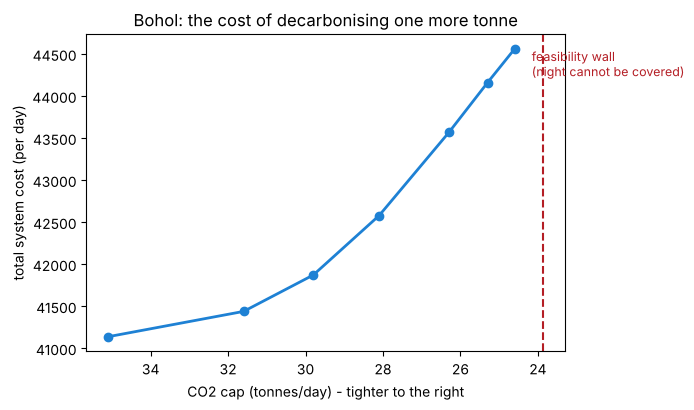

saved figures/07_tradeoff.png


In [7]:
ok = curve[curve.feasible == "yes"]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(ok["CO2 cap (t)"], ok["cost"], "o-", color="#1E81D4", lw=2)
ax.axvline(e0 * 0.68, color="#B41E25", ls="--", lw=1.5)
ax.text(e0 * 0.68 + 0.3, ok["cost"].max(), "feasibility wall\n(night cannot be covered)",
        color="#B41E25", fontsize=9, va="top")
ax.invert_xaxis()                      # tighter cap to the right
ax.set_xlabel("CO2 cap (tonnes/day) - tighter to the right")
ax.set_ylabel("total system cost (per day)")
ax.set_title("Bohol: the cost of decarbonising one more tonne")
fig.tight_layout(); fig.savefig(FIG / "07_tradeoff.png", dpi=130); plt.show()
print("saved figures/07_tradeoff.png")

## Summary of Chapter 7

- `p_nom_extendable=True` turns capacity into a decision; `capital_cost`
  (annualised per day) lets the solver weigh **building vs buying fuel**.
- Left to cost alone, the least-cost Bohol island is **already mostly renewable**
  (solar + wind + an 8 h battery) and emits little - clean is cheap here.
- A **CO2 cap** does bite once we can invest: tightening it from 100 % to 70 % of
  today's emissions **raises cost by ~8 %** as the model over-builds solar and
  storage.
- Below ~70 % the problem is **infeasible with a short battery**: the real
  bottleneck is covering the night, which needs long-duration storage or firm
  capacity. That honest limit is the whole point of planning with a model.
- Next chapter we put every tool together in one capstone case study.